# East Africa Crop Season Calendar (NDVI)

Normal season start, peak and end for 242 units, and the 2026 onset. A free sample from [NuaSense](https://agriculture-data.com), East African agricultural data; also on [Hugging Face](https://huggingface.co/datasets/nuasense/east-africa-season-onset-ndvi) (CC BY-NC 4.0).

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def load(name, hf_url):
    # On Kaggle the CSV sits under /kaggle/input; in Colab or on your machine the same table
    # is read straight from Hugging Face.
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"**/{name}", recursive=True)
    return pd.read_csv(hits[0]) if hits else pd.read_parquet(hf_url)

df = load("east_africa_crop_season_calendar_2026.csv", "https://huggingface.co/datasets/nuasense/east-africa-season-onset-ndvi/resolve/main/data/seasons/seasons.parquet")
print(f"{len(df):,} rows")
df.head()

469 rows


,country,unit_id,unit_name,season,detectable,trough_decade,onset_decade,peak_decade,senescence_decade,onset_label,...,senescence_label,trough_ndvi,peak_ndvi,amplitude,onset_threshold_ndvi,onset_decade_2026,shift_days_2026,status_2026,verdict_2026,readings_2026_until
0,KE,baringo,Baringo,1,True,6.0,10.0,15,4.0,early Apr,...,early Feb,0.33,0.58,0.24,0.38,6.0,-40.0,early,started about 40 days early,mid Oct
1,KE,baringo,Baringo,2,False,NaN,NaN,25,NaN,NaN,...,NaN,0.54,0.55,0.01,NaN,NaN,NaN,undetectable,Seasonal swing under 0.05 NDVI — this unit has...,mid Oct
2,KE,bomet,Bomet,1,True,30.0,33.0,2,6.0,late Nov,...,late Feb,0.66,0.73,0.07,0.67,NaN,NaN,awaiting_data,too early to tell — this year's satellite read...,mid Oct
3,KE,bomet,Bomet,2,True,7.0,9.0,16,24.0,late Mar,...,late Aug,0.66,0.73,0.07,0.67,14.0,50.0,late,started about 50 days late,mid Oct
4,KE,bungoma,Bungoma,1,True,7.0,10.0,17,5.0,early Apr,...,mid Feb,0.46,0.70,0.24,0.51,NaN,NaN,green_all_along,green all along — this year never dipped below...,mid Oct


## How 2026 is going

Status of each season against the unit's own 2018-2025 normal. `green_all_along` means the unit never dipped below the start level, so there is no start to date: it is not a failed season.

In [2]:
pd.crosstab(df.status_2026, df.country)

country,KE,RW,TZ,UG
status_2026,,,,
awaiting_data,28,14,22,3
early,26,3,3,68
green_all_along,15,1,0,67
late,1,22,1,36
late_so_far,2,15,2,28
not_due,0,0,7,0
on_time,10,3,6,7
undetectable,12,2,9,56


## When the season normally starts

Units by the month their normal green-up begins, first and second season.

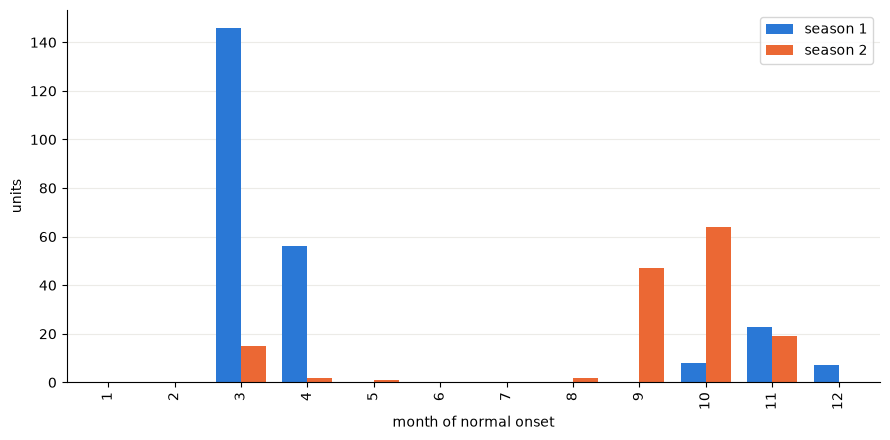

In [3]:
d = df[df.detectable].copy()
d["onset_month"] = ((d.onset_decade - 1) // 3 + 1).astype("Int64")
t = pd.crosstab(d.onset_month, d.season).reindex(range(1, 13), fill_value=0)
t.columns = [f"season {c}" for c in t.columns]
ax = t.plot.bar(color=[BLUE, ORANGE], width=0.75)
ax.set_xlabel("month of normal onset"); ax.set_ylabel("units"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## Kenya's counties

Normal start, peak and end of the long rains, and 2026.

In [4]:
ke = df[(df.country == "KE") & (df.season == 1)]
ke[["unit_name", "onset_label", "peak_label", "senescence_label", "status_2026", "shift_days_2026"]].sort_values("unit_name")

,unit_name,onset_label,peak_label,senescence_label,status_2026,shift_days_2026
0,Baringo,early Apr,late May,early Feb,early,-40.0
2,Bomet,late Nov,mid Jan,late Feb,awaiting_data,NaN
4,Bungoma,early Apr,mid Jun,mid Feb,green_all_along,NaN
6,Busia,late Mar,early Jun,mid Feb,green_all_along,NaN
8,Elgeyo-Marakwet,late Mar,mid Jun,mid Feb,green_all_along,NaN
10,Embu,late Mar,mid May,late Jul,on_time,0.0
12,Garissa,late Mar,early May,early Aug,on_time,0.0
14,Homa Bay,early Apr,early Jun,late Feb,green_all_along,NaN
16,Isiolo,early Apr,mid May,mid Jul,early,-10.0
18,Kajiado,mid Mar,mid May,early Jul,early,-10.0


## The full data

This sample is a snapshot. The NuaSense API recomputes it as each new satellite decade arrives, with the full normal and 2026 curves per unit.

```
pip install nuasense
```

A key with a free monthly allowance comes from [platform.nuasense.com](https://platform.nuasense.com/start). On Kaggle, store it as a secret named `NUASENSE_API_KEY` (Add-ons → Secrets). Fields and filters: [agriculture-data.com](https://agriculture-data.com/datasets/demand-and-crop-stress/demand-indices/).

In [5]:
# Runs only when a NuaSense key is available (Kaggle secret NUASENSE_API_KEY or an environment variable).
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("NUASENSE_API_KEY", UserSecretsClient().get_secret("NUASENSE_API_KEY"))
except Exception:
    pass

if os.environ.get("NUASENSE_API_KEY"):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nuasense"], check=False)
    import nuasense
    ns = nuasense.Client()
    answer = ns.analysis("/analytics/season", county="nakuru", country="ke")
    print(answer["this_year_readings_until"], [s.get("status") for s in answer["seasons"]])
else:
    print("No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.")

No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.
